In [25]:
from datasets import load_dataset
import pandas as pd

ds = load_dataset("liri-uzh/cfpb-complaints-mini")
train = ds["train"].to_pandas()
test = ds["test"].to_pandas()
train.shape, test.shape

((6469, 3), (1635, 3))

In [26]:
from sklearn.feature_extraction.text import TfidfVectorizer

vec = TfidfVectorizer()
X_train = vec.fit_transform(train["text"])
X_test = vec.transform(test["text"])
print(X_train.shape, X_test.shape)
len(vec.get_feature_names_out())

(6469, 16262) (1635, 16262)


16262

In [27]:
# create it with max_iter=1000 (the default often stops before it has finished learning)
# call .fit(X_train, train["label"])

from sklearn.linear_model import LogisticRegression 

model = LogisticRegression(max_iter=1000)
model.fit(X_train, train["label"])

LogisticRegression(max_iter=1000)

In [28]:
from sklearn.metrics import f1_score, classification_report

y_pred = model.predict(X_test)                         # model guesses a label for each test complaint
print(f1_score(test["label"], y_pred, average="macro"))  # one number: macro F1
print(classification_report(test["label"], y_pred))      # per-class precision, recall, F1

0.8305804292515632
                  precision    recall  f1-score   support

    bank_account       0.68      0.77      0.72       240
     credit_card       0.85      0.82      0.83       219
credit_reporting       0.81      0.86      0.83       216
 debt_collection       0.83      0.80      0.81       240
  money_transfer       0.75      0.72      0.73       240
        mortgage       0.95      0.90      0.92       240
    student_loan       0.97      0.95      0.96       240

        accuracy                           0.83      1635
       macro avg       0.83      0.83      0.83      1635
    weighted avg       0.83      0.83      0.83      1635



In [29]:
import time
import numpy as np

times = []
for text in test["text"].head(200):
    start = time.perf_counter()
    model.predict(vec.transform([text]))       # full path: text -> numbers -> label
    times.append((time.perf_counter() - start) * 1000)   # convert seconds to ms

print("median ms:", np.median(times))
print("p95 ms:", np.percentile(times, 95))

median ms: 0.5332089931471273
p95 ms: 1.0726080567110323


In [30]:
from sentence_transformers import SentenceTransformer

emb_model = SentenceTransformer("BAAI/bge-small-en-v1.5")   # downloads ~130 MB the first time

E_train = emb_model.encode(train["text"].tolist(), batch_size=64, show_progress_bar=True)
E_test  = emb_model.encode(test["text"].tolist(),  batch_size=64, show_progress_bar=True)

print(E_train.shape, E_test.shape)

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 6938.15it/s]
BertModel LOAD REPORT from: BAAI/bge-small-en-v1.5
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Batches: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████| 26/26 [00:45<00:00,  1.76s/it]

(6469, 384) (1635, 384)


In [31]:
# create it with max_iter=1000 (the default often stops before it has finished learning)
# call .fit(X_train, train["label"])

from sklearn.linear_model import LogisticRegression 

model_emb = LogisticRegression(max_iter=1000)
model_emb.fit(E_train, train["label"])

LogisticRegression(max_iter=1000)

In [32]:
y_pred_emb = model_emb.predict(E_test)                         # model guesses a label for each test complaint
print(f1_score(test["label"], y_pred_emb, average="macro"))  # one number: macro F1
print(classification_report(test["label"], y_pred_emb))   

0.8254825042207015
                  precision    recall  f1-score   support

    bank_account       0.71      0.75      0.73       240
     credit_card       0.81      0.76      0.79       219
credit_reporting       0.80      0.86      0.83       216
 debt_collection       0.82      0.80      0.81       240
  money_transfer       0.75      0.74      0.74       240
        mortgage       0.94      0.92      0.93       240
    student_loan       0.95      0.95      0.95       240

        accuracy                           0.83      1635
       macro avg       0.83      0.83      0.83      1635
    weighted avg       0.83      0.83      0.83      1635



In [33]:
times = []
for text in test["text"].head(200):
    start = time.perf_counter()
    model_emb.predict(emb_model.encode([text]))       # full path: text -> numbers -> label
    times.append((time.perf_counter() - start) * 1000)   # convert seconds to ms

print("median ms:", np.median(times))
print("p95 ms:", np.percentile(times, 95))

median ms: 37.71606250666082
p95 ms: 82.40738304448313


## Decision: TF-IDF stays the baseline. Same accuracy at a fraction of the cost.

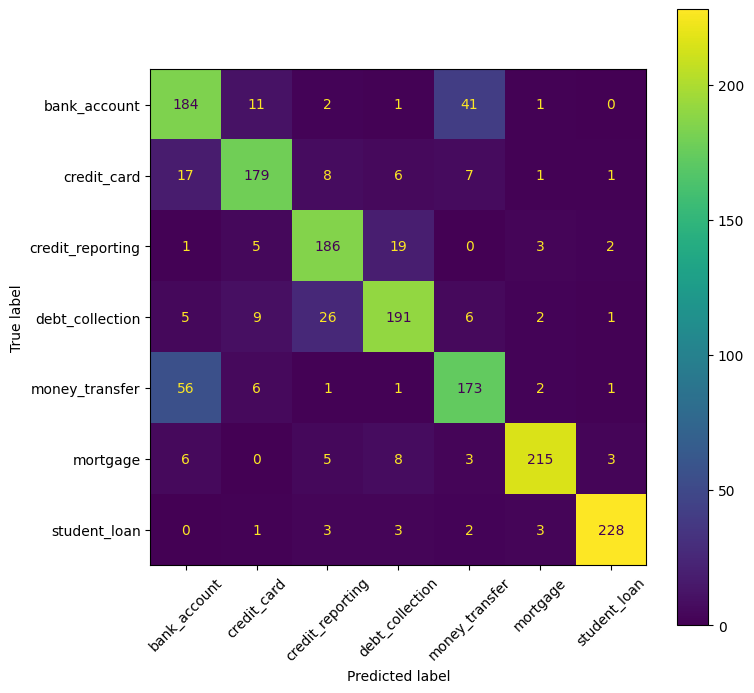

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(test["label"], y_pred, ax=ax, xticks_rotation=45)
plt.show()

In [35]:
mask = (test["label"] == "money_transfer") & (y_pred == "bank_account")
for t in test[mask]["text"].head(5):
    print("-", t[:500])
    print()

- I had both a USAA checking and a savings accounts for the past 3 or 4 years. I have been attacked by attempted cyber security breaches for the past year. On XX/XX/XXXX  I was called by a person who claimed to be a USAA agent seeking to help me with the cyber security attacks, they acted like any other USAA agent, and had all of my information just like any other USAA agent I had ever interacted with in the past. They were actually a hacker who either drained both of my accounts, or assisted in d

- I tried to make payments form my Cash App account but was told that for security purposes the payments did not go through and would be refunded to my account after a few business days. The payments were made between Between XX/XX/XXXX and XX/XX/XXXX of XXXX. I assumed the {$420.00} would eventually show up in my Cash App account. 
Note : My Cash App account was brand new established by my friend who asked me to get a Cash App account so he could pay me {$750.00}. In order to create the acc

## Conclusion:

1. **Results:** TF-IDF + LR macro F1 0.83, bge-small + LR 0.83. A tie, so TF-IDF is kept because it's cheaper.
2. **Main error:** bank_account ↔ money_transfer, 97 of 480 confused.
3. **Cause:** consumers choose the product themselves, and scams or failed transfers fit both. That's label noise.
4. **Implication:** route low-confidence complaints to a human. debt_collection recall of 0.80 is the real risk.